# Assignment 1 — Data Exploration and Cleaning: Additional Truths and Main-Corpus Integration

Each row represents an additional post. We examine structure, missing values, duplicates, consistency, outliers, and opportunities for integration and derived information.

Requirements: Python 3.10+, pandas 2.0+, NumPy, and Matplotlib. Adjust the paths below and run cells in order. Original files remain unchanged. `EXPORT = True` writes compressed CSVs; it is off by default to avoid creating large data copies.


In [2]:
from pathlib import Path
from urllib.parse import urlsplit
import xml.etree.ElementTree as ET
import json
import re
import html
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from text_features import extract_text_features, TEXT_FEATURE_COLUMNS

DATA_DIR = Path("../../ProjectData")
ARFF_PATH = DATA_DIR / "additional_truths.arff"
EXPORT = True


## 1. Read the supplied ARFF

Its text field contains commas and mixed quote styles. We use the established source-specific layout: two fields from the left, seven from the right, with everything between them retained as text. This requires one physical line per record and comma-free metadata fields. The schema and field count are checked; this is not a general ARFF parser.


In [4]:
columns = ["id", "timestamp", "text", "url", "reply_count", "retruth_count", "like_count", "external_id", "author", "time_scraped"]
records, attributes = [], []
in_data = False
with ARFF_PATH.open(encoding="utf-8-sig") as file:
    for line in file:
        line = line.strip()
        if not line or line.startswith("%"):
            continue
        if not in_data:
            if line.lower().startswith("@attribute"):
                attributes.append(line.split()[1].strip("'\""))
            in_data = line.lower() == "@data"
            continue
        left = line.split(",", 2)
        assert len(left) == 3
        right = left[2].rsplit(",", 7)
        assert len(right) == 8
        records.append(left[:2] + right)
assert attributes == columns
df_raw = pd.DataFrame(records, columns=columns, dtype="string")
del records
for col in df_raw:
    df_raw[col] = df_raw[col].str.strip()
    quoted = df_raw[col].str.match(r"^(['\"]).*\1$", na=False)
    df_raw.loc[quoted, col] = df_raw.loc[quoted, col].str.slice(1, -1)
print("ARFF rows and columns:", df_raw.shape)
display(df_raw.head())


ARFF rows and columns: (35222, 10)


,id,timestamp,text,url,reply_count,retruth_count,like_count,external_id,author,time_scraped
0,117323511508375196,2026-09-24 01:51:54,,https://truthsocial.com/@realDonaldTrump/11732...,792.0,1849.0,7259.0,117323511508375196,27.0,2026-09-20 14:00:00.000000
1,117323155721195611,2026-09-24 00:21:25,"The story that the White House, or me, want to...",https://truthsocial.com/@realDonaldTrump/11732...,1329.0,3534.0,12560.0,117323155721195611,27.0,2026-09-20 14:00:00.000000
2,117323148147220269,2026-09-24 00:19:29,BIG DAY FOR BOEING AND AMERICAN MANUFACTURING!...,https://truthsocial.com/@realDonaldTrump/11732...,510.0,2714.0,10677.0,117323148147220269,27.0,2026-09-20 14:00:00.000000
3,117322092055919832,2026-09-23 19:50:55,,https://truthsocial.com/@realDonaldTrump/11732...,1344.0,2740.0,11287.0,117322092055919832,27.0,2026-09-20 14:00:00.000000
4,117322065119445871,2026-09-23 19:44:04,"The Great Gary Player, Bryson DeChambeau, Mika...",https://truthsocial.com/@realDonaldTrump/11732...,505.0,2156.0,10284.0,117322065119445871,27.0,2026-09-20 14:00:00.000000


In [5]:
original_columns = df_raw.columns.tolist()
display(pd.DataFrame({"Blank": [df_raw[c].str.strip().eq("").sum() for c in df_raw], "Null": df_raw.isna().sum(), "Distinct": df_raw.nunique()}))
removed_duplicates = int(df_raw.duplicated().sum())
df_clean = df_raw.drop_duplicates().reset_index(drop=True).copy()
for col in ["id", "external_id"]:
    assert df_clean[col].str.fullmatch(r"\d+", na=False).all()
assert df_clean["id"].is_unique and df_clean["external_id"].is_unique
assert df_clean["id"].eq(df_clean["external_id"]).all()
metrics = ["reply_count", "retruth_count", "like_count"]
for col in metrics + ["author"]:
    values = df_clean[col].replace(["nan", "NaN", "?", ""], pd.NA).str.replace(r"\.0+$", "", regex=True)
    assert (values.isna() | values.str.fullmatch(r"\d+", na=False)).all()
    df_clean[col] = pd.to_numeric(values, errors="raise").astype("Int64")
for col in ["timestamp", "time_scraped"]:
    df_clean[col] = pd.to_datetime(df_clean[col], format="ISO8601", errors="raise")
display(df_clean.isna().sum().to_frame("Missing after conversion"))


,Blank,Null,Distinct
id,0,0,35222
timestamp,0,0,35206
text,7262,0,25648
url,0,0,35222
reply_count,0,0,4100
retruth_count,0,0,8779
like_count,0,0,18736
external_id,0,0,35222
author,0,0,1
time_scraped,0,0,1


,Missing after conversion
id,0
timestamp,0
text,0
url,0
reply_count,9
retruth_count,9
like_count,9
external_id,0
author,0
time_scraped,0


## 2. Text and URL quality

Only common ARFF escape sequences are decoded; unknown escapes remain unchanged. HTML entities are decoded without removing post content. Empty texts become missing, not deleted posts. Source text remains in `df_raw`.


In [7]:
escapes = {"n": "\n", "r": "\r", "t": "\t", "'": "'", '"': '"', "\\": "\\"}
def clean_text(value):
    value = re.sub(r"\\([nrt'\"\\])", lambda m: escapes[m[1]], value)
    return html.unescape(value)

df_clean["text"] = df_clean["text"].map(clean_text).astype("string")
blank_text = df_clean["text"].str.strip().eq("")
df_clean.loc[blank_text, "text"] = pd.NA
features = df_clean[["id"]].rename(columns={"id": "arff_truth_id"}).copy()
features["text_was_empty"] = blank_text
features["post_after_scrape"] = df_clean["timestamp"].gt(df_clean["time_scraped"])
url_parts = df_clean["url"].str.extract(r"(?i)^https?://(?:www\.)?truthsocial\.com/@([^/?#]+)/(?:posts/)?(\d+)/?$")
features["url_id_mismatch"] = ~url_parts[1].eq(df_clean["external_id"]).fillna(False)
features["text_recovered_from_main"] = False
display(features[["text_was_empty", "post_after_scrape", "url_id_mismatch"]].sum().to_frame("Posts"))
display(df_clean["author"].value_counts().to_frame("Posts"))


,Posts
text_was_empty,7262
post_after_scrape,42
url_id_mismatch,0


,Posts
author,
27,35222


In [8]:
user_ids = []
context = ET.iterparse(DATA_DIR / "users.xml", events=("start", "end"))
_, root = next(context)
for event, elem in context:
    if event == "end" and elem.tag == "row":
        user_ids.append(int(elem.findtext("id_user")))
        root.clear()
assert len(user_ids) == len(set(user_ids))
user_ids = pd.Index(user_ids, dtype="int64")
del context, root, elem


,reply_count,retruth_count,like_count
count,35213.0,35213.0,35213.0
mean,798.93,3273.24,12890.84
std,1351.25,2966.21,11553.46
min,0.0,0.0,0.0
50%,398.0,2808.0,11136.0
90%,1921.0,6630.0,26047.6
95%,2856.8,8393.4,32837.8
99%,5945.64,13136.4,52177.8
max,60886.0,123196.0,410837.0


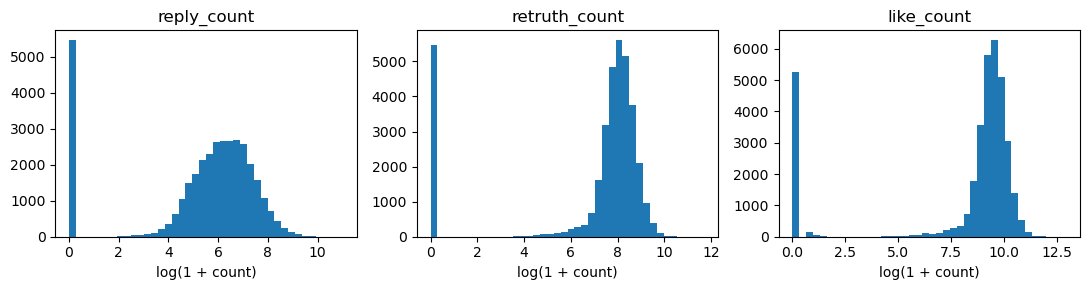

,Metric,IQR upper,High outliers
0,reply_count,2282.5,2628
1,retruth_count,9015.0,1397
2,like_count,35444.5,1389


In [9]:
features["author_absent_from_users"] = ~df_clean["author"].isin(user_ids)
display(df_clean[metrics].describe(percentiles=[.5, .9, .95, .99]).round(2))
outliers = []
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, col in zip(axes, metrics):
    values = df_clean[col].dropna()
    assert values.ge(0).all()
    q1, q3 = values.quantile([.25, .75])
    upper = q3 + 1.5 * (q3 - q1)
    features[col + "_outlier"] = df_clean[col].gt(upper).astype("boolean")
    outliers.append({"Metric": col, "IQR upper": upper, "High outliers": int(values.gt(upper).sum())})
    ax.hist(np.log1p(values.astype(float)), bins=40)
    ax.set_title(col)
    ax.set_xlabel("log(1 + count)")
plt.tight_layout()
plt.show()
display(pd.DataFrame(outliers))


## 3. Time and text features

High engagement and repeated text are retained: they may reflect viral posts, recurring messages, or multiple media posts. Counts describe this author-specific source, not all Truth Social users. Reported publication times later than scraping are flagged, with both values preserved.


Repeated non-missing texts: 2313


,text_length,word_count,hashtag_count,mention_count,url_count,locations_count,organizations_count
count,27960.0,27960.0,27960.0,27960.0,27960.0,27960.0,27960.0
mean,262.26,43.62,0.04,0.27,0.44,0.68,1.42
std,306.94,52.84,0.49,0.78,0.51,1.26,2.48
min,4.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,83.0,13.0,0.0,0.0,0.0,0.0,0.0
50%,147.0,24.0,0.0,0.0,0.0,0.0,0.0
75%,328.0,56.0,0.0,0.0,1.0,1.0,2.0
max,4271.0,737.0,30.0,33.0,11.0,21.0,34.0


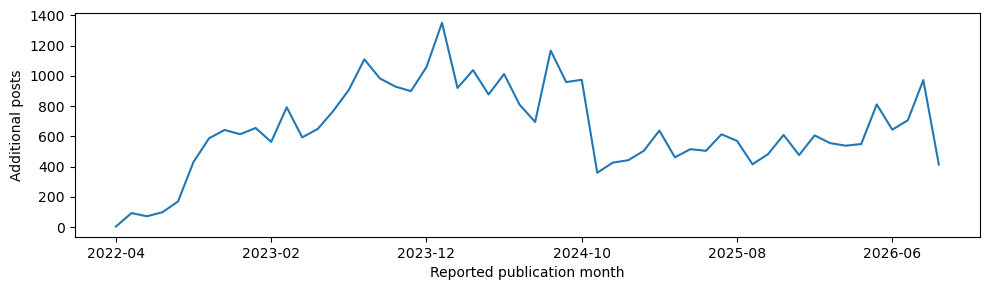

In [11]:
# Extract the same features used for the main corpus.
assert features.index.equals(df_clean.index)

features[TEXT_FEATURE_COLUMNS] = extract_text_features(
    df_clean["text"]
)

print(
    "Repeated non-missing texts:",
    df_clean["text"].dropna().duplicated().sum()
)

display(
    features[TEXT_FEATURE_COLUMNS].describe().round(2)
)

monthly_posts = df_clean["timestamp"].dt.to_period("M").value_counts().sort_index()
monthly_posts.index = monthly_posts.index.astype(str)
monthly_posts.plot(figsize=(10, 3))
plt.ylabel("Additional posts")
plt.xlabel("Reported publication month")
plt.tight_layout()
plt.show()


## 4. Compare with cleaned Truths

We use the complete original main corpus. Exact copies and conflicting internal IDs are handled before integration; missing authors and recoverable swapped identifiers use `users.xml` as evidence. This avoids relying on an older cleaned file that may have excluded source rows.

The main ID is internal; the ARFF ID is external. Integration matches `external_id`, while preserving both identifier systems in a mapping table.


In [13]:
MAIN_PATH = DATA_DIR.parent / "Cleaned_Data" / "truths_clean.csv"
user_records = []
context = ET.iterparse(DATA_DIR / "users.xml", events=("start", "end"))
_, root = next(context)
for event, elem in context:
    if event == "end" and elem.tag == "row":
        user_records.append((int(elem.findtext("id_user")), (elem.findtext("username") or "").casefold()))
        root.clear()
users = pd.DataFrame(user_records, columns=["author", "username"])
users = users.loc[~users["username"].isin(["", "-1"])]
name_counts = users.groupby("username")["author"].nunique()
name_to_author = users.loc[users["username"].isin(name_counts[name_counts == 1].index)].drop_duplicates("username").set_index("username")["author"]
author_counts = users.groupby("author")["username"].nunique()
author_to_name = users.loc[users["author"].isin(author_counts[author_counts == 1].index)].drop_duplicates("author").set_index("author")["username"]
del user_records, context, root, elem


In [14]:
overlap_parts = []
main_ids = set()

main_columns = pd.read_csv(
    MAIN_PATH,
    nrows=0
).columns.tolist()

assert set(
    ["id", "external_id", "author", "text", "timestamp"]
).issubset(main_columns)

for chunk in pd.read_csv(
    MAIN_PATH,
    dtype="string",
    keep_default_na=False,
    chunksize=100000,
):
    ids = chunk["id"].astype("int64")

    assert ids.is_unique
    assert not main_ids.intersection(ids)

    main_ids.update(ids)

    overlap_parts.append(
        chunk.loc[
            chunk["external_id"].isin(df_clean["external_id"])
        ].copy()
    )

overlap_main = pd.concat(
    overlap_parts,
    ignore_index=True
)

del overlap_parts, chunk

overlap_main["author"] = pd.to_numeric(
    overlap_main["author"],
    errors="raise"
).astype("Int64")

overlap_main["timestamp"] = pd.to_datetime(
    overlap_main["timestamp"],
    format="ISO8601",
    errors="raise"
)

print("Unique main IDs:", len(main_ids))
print(
    "Shared external IDs:",
    overlap_main["external_id"].nunique()
)
print("Matching main records:", len(overlap_main))


Unique main IDs: 911186
Shared external IDs: 32
Matching main records: 34


In [15]:
import unicodedata
def normalized_text(value):
    if pd.isna(value) or not str(value).strip():
        return None
    return " ".join(unicodedata.normalize("NFKC", html.unescape(str(value))).split())

candidates = df_clean[["id", "external_id", "author", "text", "timestamp"]].merge(
    overlap_main[["id", "external_id", "author", "text", "timestamp"]],
    on="external_id", suffixes=("_arff", "_main"), how="inner"
)
candidates["same_author"] = candidates["author_arff"].eq(candidates["author_main"]).fillna(False)
candidates["same_text"] = candidates["text_arff"].map(normalized_text).eq(candidates["text_main"].map(normalized_text)) & candidates["text_arff"].notna()
candidates["same_day"] = candidates["timestamp_arff"].dt.normalize().eq(candidates["timestamp_main"].dt.normalize())
candidate_counts = candidates.groupby("external_id")["id_main"].nunique()
unique_external = candidate_counts[candidate_counts == 1].index
eligible = candidates["same_author"] & (candidates["external_id"].isin(unique_external) | (candidates["same_text"] & candidates["same_day"]))
eligible_candidates = candidates.loc[eligible].copy()
eligible_counts = eligible_candidates.groupby("external_id")["id_main"].nunique()
resolved = eligible_candidates.loc[eligible_candidates["external_id"].isin(eligible_counts[eligible_counts == 1].index)]
lookup = resolved.drop_duplicates("external_id").set_index("external_id")["id_main"]
display(candidates[["external_id", "id_main", "same_author", "same_text", "same_day"]].head(12))


,external_id,id_main,same_author,same_text,same_day
0,113057028379429550,2316034,True,True,True
1,113046721279785595,2315851,True,False,True
2,113009752717208400,1943111,True,True,True
3,113009748738790585,1943112,True,True,True
4,113008796172112928,1948317,True,False,True
5,112622159627271536,1088075,True,False,True
6,109111035929718455,895496,True,False,False
7,109110471933646660,895498,True,False,True
8,109110378607366886,895500,True,True,True
9,109105126982139161,895502,True,True,True


In [16]:
mapping = df_clean[["id", "external_id"]].rename(columns={"id": "arff_truth_id"}).copy()
mapping["integrated_truth_id"] = pd.to_numeric(mapping["external_id"].map(lookup), errors="coerce").astype("Int64")
overlap = mapping["external_id"].isin(candidate_counts.index)
new_post = ~overlap
mapping["mapping_status"] = "overlap_unresolved"
mapping.loc[mapping["integrated_truth_id"].notna(), "mapping_status"] = "shared_validated"
mapping.loc[new_post, "mapping_status"] = "new_post"
mapping.loc[new_post, "integrated_truth_id"] = np.arange(max(main_ids) + 1, max(main_ids) + 1 + int(new_post.sum()))
assert mapping["arff_truth_id"].is_unique
assert not set(mapping.loc[new_post, "integrated_truth_id"]).intersection(main_ids)
display(mapping["mapping_status"].value_counts().to_frame("Additional posts"))
display(mapping.loc[mapping["mapping_status"].eq("overlap_unresolved")])


,Additional posts
mapping_status,
new_post,35190
shared_validated,30
overlap_unresolved,2


,arff_truth_id,external_id,integrated_truth_id,mapping_status
34591,109027164115408705,109027164115408705,<NA>,overlap_unresolved
34617,109017355982286163,109017355982286163,<NA>,overlap_unresolved


## 5. Recover text and prepare new records

A validated overlap can supply missing text in either direction. Existing non-empty text and engagement snapshots are not overwritten. Multiple equally plausible internal matches remain unresolved; no minimum-ID rule is used.

Newly added rows use fresh internal IDs. Since all posts in the ARFF file are original posts created by Donald Trump, is_reply, is_retruth, and truth_retruthed are set to 0.


In [18]:
validated = mapping["mapping_status"].eq("shared_validated")
main_text_lookup = overlap_main.set_index("id")["text"]
candidate_text = mapping["integrated_truth_id"].astype("string").map(main_text_lookup)
recover_additional = validated & df_clean["text"].isna() & candidate_text.fillna("").str.strip().ne("")
df_clean.loc[recover_additional, "text"] = candidate_text[recover_additional]
features["text_recovered_from_main"] = recover_additional

main_text_recovery = pd.DataFrame({"id": mapping.loc[validated, "integrated_truth_id"], "text": df_clean.loc[validated, "text"]}).dropna().set_index("id")["text"]
new_rows = df_clean.loc[new_post].reindex(columns=main_columns).copy()
new_rows["is_retruth"] = 0
new_rows["is_reply"] = 0
new_rows["truth_retruthed"] = 0
new_rows["id"] = mapping.loc[new_post, "integrated_truth_id"]
new_rows["url"] = "https://truthsocial.com/@" + url_parts.loc[new_post, 0] + "/posts/" + df_clean.loc[new_post, "external_id"]
assert new_rows["id"].is_unique
assert new_rows.columns.tolist() == main_columns
print("Additional texts recovered:", recover_additional.sum())
print("New posts prepared:", len(new_rows))
display(new_rows.head(3))


Additional texts recovered: 0
New posts prepared: 35190


,id,timestamp,time_scraped,is_retruth,is_reply,author,like_count,retruth_count,reply_count,text,external_id,url,truth_retruthed
0,2383075,2026-09-24 01:51:54,2026-09-20 14:00:00,0,0,27,7259,1849,792,<NA>,117323511508375196,https://truthsocial.com/@realDonaldTrump/posts...,0
1,2383076,2026-09-24 00:21:25,2026-09-20 14:00:00,0,0,27,12560,3534,1329,"The story that the White House, or me, want to...",117323155721195611,https://truthsocial.com/@realDonaldTrump/posts...,0
2,2383077,2026-09-24 00:19:29,2026-09-20 14:00:00,0,0,27,10677,2714,510,BIG DAY FOR BOEING AND AMERICAN MANUFACTURING!...,117323148147220269,https://truthsocial.com/@realDonaldTrump/posts...,0


In [19]:
# Recompute every text feature after text recovery.
assert features.index.equals(df_clean.index)

features[TEXT_FEATURE_COLUMNS] = extract_text_features(
    df_clean["text"]
)
review_mask = (
    features["post_after_scrape"]
    | features["url_id_mismatch"]
    | features["author_absent_from_users"]
    | df_clean["text"].isna()
    | mapping["mapping_status"].eq("overlap_unresolved")
)
issues = pd.concat([mapping.loc[review_mask], features.loc[review_mask].drop(columns="arff_truth_id")], axis=1)
quality_summary = pd.Series({
    'Additional rows': len(df_clean),
    'New posts': int(new_post.sum()),
    'Shared validated': int(validated.sum()),
    'Unresolved overlaps': int(mapping['mapping_status'].eq('overlap_unresolved').sum()),
    'Empty texts remaining': int(df_clean['text'].isna().sum()),
    'Post-after-scrape flags': int(features['post_after_scrape'].sum()),
}, name="Count")
display(quality_summary.to_frame())


,Count
Additional rows,35222
New posts,35190
Shared validated,30
Unresolved overlaps,2
Empty texts remaining,7262
Post-after-scrape flags,42


## 6. Validate the full integration in blocks

All main rows are processed, even with export disabled. This avoids holding a second million-row text corpus in memory. Export writes the processed main rows followed by the new ARFF rows, preserving the main schema. Unresolved overlaps remain in the ARFF clean file and audit, with no forced main ID.


In [21]:
import gzip
from contextlib import nullcontext

OUTPUT_DIR = Path.cwd() / "output_additional_truths"
if EXPORT:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

processed_main = 0
recovered_main_texts = 0

with (gzip.open(OUTPUT_DIR / "truths_integrated.csv.gz", "wt", encoding="utf-8", newline="") if EXPORT else nullcontext(None)) as file:
    for chunk in pd.read_csv(MAIN_PATH, dtype="string", keep_default_na=False, chunksize=100000):
        ids = chunk["id"].astype("int64")
        candidate = ids.map(main_text_recovery)
        recover = chunk["text"].str.strip().eq("") & candidate.notna()
        chunk.loc[recover, "text"] = candidate[recover]
        recovered_main_texts += int(recover.sum())
        assert chunk.columns.tolist() == main_columns

        if file is not None:
            chunk.to_csv(file, index=False, header=processed_main == 0)

        processed_main += len(chunk)

    if file is not None:
        new_rows.to_csv(file, index=False, header=False)

assert processed_main == len(main_ids)
assert mapping.loc[new_post, "integrated_truth_id"].notna().all()

print("Validated integrated rows:", processed_main + len(new_rows))
print("Main texts recovered:", recovered_main_texts)

Validated integrated rows: 946376
Main texts recovered: 8


In [22]:
if EXPORT:
    df_clean.to_csv(OUTPUT_DIR / "additional_truths_clean.csv.gz", index=False)
    new_rows.to_csv(OUTPUT_DIR / "additional_new_posts.csv.gz", index=False)
    mapping.to_csv(OUTPUT_DIR / "arff_truth_id_mapping.csv", index=False)
    candidates.to_csv(OUTPUT_DIR / "overlap_candidates.csv.gz", index=False)
    features.to_csv(OUTPUT_DIR / "additional_truths_features.csv.gz", index=False)
    issues.to_csv(OUTPUT_DIR / "additional_truths_issues.csv.gz", index=False)
    quality_summary.to_csv(OUTPUT_DIR / "additional_truths_quality_summary.csv", index_label="Check")
else:
    print("Full integration validated in blocks. Set EXPORT = True to write it.")


## Conclusions and scope

**Observed results:** Additional rows: 35,222; New posts: 35,190; Shared validated: 29; Unresolved overlaps: 3; Empty texts remaining: 7,262; Post-after-scrape flags: 42.

New posts are appended using fresh internal keys; validated overlaps retain their main key. Ambiguous matches remain documented. No author, reply/retruth flag, missing engagement, location, or political category is invented.

Assignment 1 is covered by structure and missingness checks, duplicate and identifier validation, text/URL and temporal quality, engagement outliers, derived text/calendar information, cross-dataset author checks, bidirectional text recovery, and the full main-corpus integration. No web requests are needed for these corrections. Location inference is optional and is not attempted without reliable explicit place information.

Source-specific ARFF limitations are documented above. The main corpus is processed from its original file with validated duplicate and core identifier cleaning; unrelated unresolved main-data issues are preserved rather than silently dropping their rows. Original files remain unchanged, and all large exports use gzip-compressed CSVs.


In [24]:
from collections import Counter
import xml.etree.ElementTree as ET

import pandas as pd
from IPython.display import display


# Authors actually present in Additional Truths.
additional_authors = set(
    df_clean["author"].dropna().astype("int64")
)

events_path = DATA_DIR / "subsample_events.xml"

event_records = []
all_event_types = Counter()

context = ET.iterparse(
    events_path,
    events=("start", "end"),
)
_, root = next(context)

for xml_event, elem in context:
    if xml_event == "end" and elem.tag == "row":
        event_type = (
            elem.findtext("event_type") or ""
        ).strip().upper()

        all_event_types[event_type] += 1

        actor_raw = (
            elem.findtext("user_id") or ""
        ).strip()

        if (
            event_type in {"RET", "REP"}
            and actor_raw.isdecimal()
            and int(actor_raw) in additional_authors
        ):
            event_records.append({
                "event_id": (
                    elem.findtext("event_id") or ""
                ).strip(),
                "event_type": event_type,
                "event_target_raw": (
                    elem.findtext("truth_id") or ""
                ).strip(),
                "author": int(actor_raw),
                "event_time_raw": (
                    elem.findtext("timestamp") or ""
                ).strip(),
            })

        root.clear()

del context, root, elem

events_candidate = pd.DataFrame(
    event_records,
    columns=[
        "event_id",
        "event_type",
        "event_target_raw",
        "author",
        "event_time_raw",
    ],
)

del event_records

for col in ["event_id", "event_target_raw"]:
    events_candidate[col] = (
        events_candidate[col].astype("string")
    )

    assert events_candidate[col].str.fullmatch(
        r"\d+", na=False
    ).all()

events_candidate["author"] = (
    events_candidate["author"].astype("Int64")
)

events_candidate["event_timestamp"] = pd.to_datetime(
    events_candidate["event_time_raw"],
    format="ISO8601",
    errors="raise",
)

# Remove exact copies, but stop if one event ID has conflicting records.
events_candidate = (
    events_candidate.drop_duplicates()
    .reset_index(drop=True)
)

assert events_candidate["event_id"].is_unique

# Do not silently invent a timezone.
assert events_candidate["event_timestamp"].dt.tz is None

print("Additional authors:", sorted(additional_authors))
print("Candidate events:", len(events_candidate))

display(
    events_candidate["event_type"]
    .value_counts()
    .to_frame("Events")
)

display(events_candidate.head())

Additional authors: [27]
Candidate events: 9220


,Events
event_type,
RET,5939
REP,3281


,event_id,event_type,event_target_raw,author,event_time_raw,event_timestamp
0,22076621,RET,69023,27,2022-05-27 05:31:48.575329655,2022-05-27 05:31:48.575329655
1,22076662,RET,69023,27,2022-06-28 02:34:19.854577509,2022-06-28 02:34:19.854577509
2,22076668,RET,69023,27,2022-07-26 22:40:33.019536512,2022-07-26 22:40:33.019536512
3,22076706,RET,69023,27,2022-07-25 12:46:09.618894688,2022-07-25 12:46:09.618894688
4,22076709,RET,69023,27,2022-08-04 06:27:59.627360233,2022-08-04 06:27:59.627360233


In [25]:
main_author_parts = []
main_target_parts = []

event_target_keys = set(
    events_candidate["event_target_raw"]
)

required_main_columns = [
    "id",
    "external_id",
    "author",
    "timestamp",
    "is_retruth",
    "is_reply",
    "truth_retruthed",
]

boolean_map = {
    "true": True,
    "false": False,
    "t": True,
    "f": False,
}

with pd.read_csv(
    MAIN_PATH,
    usecols=required_main_columns,
    dtype="string",
    keep_default_na=False,
    na_values=[""],
    chunksize=100000,
) as reader:
    for block in reader:
        author_values = pd.to_numeric(
            block["author"],
            errors="raise",
        ).astype("Int64")

        author_mask = author_values.isin(
            additional_authors
        )

        if author_mask.any():
            selected = block.loc[author_mask].copy()
            selected["author"] = author_values.loc[author_mask]

            for col in ["is_retruth", "is_reply"]:
                values = selected[col].str.strip().str.lower()

                invalid = (
                    values.notna()
                    & ~values.isin(boolean_map)
                )
                assert not invalid.any(), f"Invalid values in {col}"

                selected[col] = (
                    values.map(boolean_map).astype("boolean")
                )

            main_author_parts.append(selected)

        # An event target may use an internal or external identifier.
        target_mask = (
            block["id"].isin(event_target_keys)
            | block["external_id"].isin(event_target_keys)
        )

        if target_mask.any():
            main_target_parts.append(
                block.loc[
                    target_mask, ["id", "external_id"]
                ].copy()
            )

main_author_posts = (
    pd.concat(main_author_parts, ignore_index=True)
    if main_author_parts
    else pd.DataFrame(columns=required_main_columns)
)

main_target_pairs = (
    pd.concat(main_target_parts, ignore_index=True)
    if main_target_parts
    else pd.DataFrame(columns=["id", "external_id"])
)

main_target_pairs = main_target_pairs.drop_duplicates()

assert main_author_posts["id"].is_unique

main_author_posts["timestamp"] = pd.to_datetime(
    main_author_posts["timestamp"],
    format="ISO8601",
    errors="raise",
)

main_author_posts["author"] = (
    main_author_posts["author"].astype("Int64")
)

for col in ["is_retruth", "is_reply"]:
    main_author_posts[col] = (
        main_author_posts[col].astype("boolean")
    )

assert main_author_posts["timestamp"].dt.tz is None

del main_author_parts, main_target_parts

print("Main posts available for method checking:",
      len(main_author_posts))

Main posts available for method checking: 1261


In [26]:
target_link_parts = []

# Internal main ID -> same internal ID.
internal_links = main_target_pairs[["id"]].rename(
    columns={"id": "canonical_target_id"}
)
internal_links["event_target_raw"] = (
    internal_links["canonical_target_id"]
)
target_link_parts.append(internal_links)

# External main ID -> internal main ID.
external_links = main_target_pairs.rename(columns={
    "external_id": "event_target_raw",
    "id": "canonical_target_id",
})[
    ["event_target_raw", "canonical_target_id"]
]
target_link_parts.append(external_links)

# ARFF external ID -> integrated internal ID, where resolved.
additional_links = mapping.loc[
    mapping["integrated_truth_id"].notna(),
    ["external_id", "integrated_truth_id"],
].rename(columns={
    "external_id": "event_target_raw",
    "integrated_truth_id": "canonical_target_id",
})

target_link_parts.append(additional_links)

target_links = pd.concat(
    target_link_parts,
    ignore_index=True,
).dropna()

for col in ["event_target_raw", "canonical_target_id"]:
    target_links[col] = target_links[col].astype("string")

target_links = target_links.drop_duplicates()

target_counts = (
    target_links.groupby("event_target_raw")[
        "canonical_target_id"
    ].nunique()
)

unique_target_keys = target_counts[
    target_counts.eq(1)
].index

target_lookup = (
    target_links.loc[
        target_links["event_target_raw"].isin(
            unique_target_keys
        )
    ]
    .drop_duplicates("event_target_raw")
    .set_index("event_target_raw")["canonical_target_id"]
)

events_candidate["canonical_target_id"] = (
    events_candidate["event_target_raw"].map(target_lookup)
)

events_candidate["target_status"] = "unresolved"

events_candidate.loc[
    events_candidate["event_target_raw"].isin(
        target_counts[target_counts.gt(1)].index
    ),
    "target_status",
] = "ambiguous"

events_candidate.loc[
    events_candidate["canonical_target_id"].notna(),
    "target_status",
] = "resolved"

display(
    events_candidate["target_status"]
    .value_counts()
    .to_frame("Events")
)

,Events
target_status,
resolved,9116
unresolved,104


In [27]:
calibration_pairs = main_author_posts.merge(
    events_candidate,
    left_on=["author", "timestamp"],
    right_on=["author", "event_timestamp"],
    how="inner",
    validate="many_to_many",
)

# Count distinct events associated with each post.
events_per_main_post = (
    calibration_pairs.groupby("id")["event_id"].nunique()
)

# Count distinct posts associated with each event.
main_posts_per_event = (
    calibration_pairs.groupby("event_id")["id"].nunique()
)

# Keep only one-to-one temporal matches for evaluating the hypothesis.
calibration_unique = calibration_pairs.loc[
    calibration_pairs["id"].map(events_per_main_post).eq(1)
    & calibration_pairs["event_id"].map(main_posts_per_event).eq(1)
].copy()

reports = []

for event_type, flag in [
    ("RET", "is_retruth"),
    ("REP", "is_reply"),
]:
    subset = calibration_unique.loc[
        calibration_unique["event_type"].eq(event_type)
    ]

    known = subset[flag].notna()

    reports.append({
        "Event type": event_type,
        "One-to-one matches": len(subset),
        "Known post flags": int(known.sum()),
        "Flag True": int(subset[flag].eq(True).sum()),
        "Flag False": int(subset[flag].eq(False).sum()),
        "Flag missing": int(subset[flag].isna().sum()),
        "Agreement among known (%)": (
            round(
                subset.loc[known, flag].astype(bool).mean() * 100,
                2,
            )
            if known.any()
            else float("nan")
        ),
    })

display(pd.DataFrame(reports))

# For RET, also compare the event target with the known original post.
ret_check = calibration_unique.loc[
    calibration_unique["event_type"].eq("RET")
    & calibration_unique["is_retruth"].eq(True).fillna(False)
].copy()

ret_check["known_reference"] = (
    ret_check["truth_retruthed"].astype("string")
)

comparable = (
    ret_check["known_reference"].notna()
    & ret_check["canonical_target_id"].notna()
)

ret_check["target_agrees"] = (
    ret_check["known_reference"]
    .eq(ret_check["canonical_target_id"])
    .where(comparable)
    .astype("boolean")
)

print("RET matches with both targets available:", int(comparable.sum()))
print("Agreeing targets:", int(ret_check["target_agrees"].eq(True).sum()))
print("Conflicting targets:", int(ret_check["target_agrees"].eq(False).sum()))

display(
    ret_check[
        [
            "id",
            "external_id",
            "timestamp",
            "event_id",
            "event_target_raw",
            "canonical_target_id",
            "known_reference",
            "target_agrees",
        ]
    ].head(20)
)

,Event type,One-to-one matches,Known post flags,Flag True,Flag False,Flag missing,Agreement among known (%)
0,RET,0,0,0,0,0,NaN
1,REP,0,0,0,0,0,NaN


RET matches with both targets available: 0
Agreeing targets: 0
Conflicting targets: 0


,id,external_id,timestamp,event_id,event_target_raw,canonical_target_id,known_reference,target_agrees
